In [1]:
from groq import Groq
import re
import httpx
import os 
from dotenv import load_dotenv, find_dotenv
from openai import OpenAI

_ = load_dotenv(find_dotenv())

In [2]:
client = OpenAI(
    base_url="https://api.groq.com/openai/v1",
    api_key=os.environ.get("GROQ_API_KEY")
)

In [3]:
chat_completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[{"role": "user", "content": "Hello world"}]
)

In [4]:
chat_completion.choices[0].message.content

'Hello! 👋 How can I assist you today?'

In [5]:
class Agent:
    def __init__(self, system=""):
        self.system = system
        self.messages = []
        if self.system:
            self.messages.append({"role": "system", "content": system})

    def __call__(self, messages):
        self.messages.append({"role": "user", "content": messages})
        result = self.execute()
        self.messages.append({"role": "assistant", "content": result})
        return result

    def execute(self):
        completion = client.chat.completions.create(
            model="qwen/qwen3.8-27b",
            temperature=0,
            messages=self.messages
        )
        return completion.choices[0].message.content

In [6]:
prompt = """
You run in a loop of Thought, Action, PAUSE, Observation.
At the end of the loop you output an Answer
Use Thought to describe your thoughts about the question you have been asked.
Use Action to run one of the actions available to you - then return PAUSE.
Observation will be the result of running those actions.

Your available actions are:

calculate:
e.g. calculate: 4 * 7 / 3
Runs a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary

average_dog_weight:
e.g. average_dog_weight: Collie
returns average weight of a dog when given the breed

Example session:

Question: How much does a Bulldog weigh?
Thought: I should look the dogs weight using average_dog_weight
Action: average_dog_weight: Bulldog
PAUSE

You will be called again with this:

Observation: A Bulldog weights 51 lbs

You then output:

Answer: A bulldog weights 51 lbs
""".strip()

In [7]:
def calculate(what):
    return eval(what)

def average_dog_weight(name):
    if name in "Scottish Terrier":
        return("Scottish Terriers average 20 lbs")
    elif name in "Border Collie":
        return("a Border Collie average weight is 37 lbs")
    elif name in "Toy Poodle":
        return("a toy poodles average weight is 7 lbs")
    else:
        return("An average dog weights 50 lbs")

known_actions = {
    "calculate": calculate,
    "average_dog_weight": average_dog_weight
}

In [8]:
abot = Agent(prompt)

In [9]:
result = abot("How much does a toy poodle weight?")
print(result)

Thought: I need to find the average weight of a Toy Poodle. I can use the average_dog_weight tool with the breed "Toy Poodle".
Action: average_dog_weight: Toy Poodle
PAUSE


In [10]:
result = average_dog_weight("Toy Poodle")
result

'a toy poodles average weight is 7 lbs'

In [11]:
next_prompt = "Observation: {}".format(result)
abot(next_prompt)

'Answer: A Toy Poodle weighs an average of 7 lbs.'

In [12]:
abot.messages

[{'role': 'system',
  'content': 'You run in a loop of Thought, Action, PAUSE, Observation.\nAt the end of the loop you output an Answer\nUse Thought to describe your thoughts about the question you have been asked.\nUse Action to run one of the actions available to you - then return PAUSE.\nObservation will be the result of running those actions.\n\nYour available actions are:\n\ncalculate:\ne.g. calculate: 4 * 7 / 3\nRuns a calculation and returns the number - uses Python so be sure to use floating point syntax if necessary\n\naverage_dog_weight:\ne.g. average_dog_weight: Collie\nreturns average weight of a dog when given the breed\n\nExample session:\n\nQuestion: How much does a Bulldog weigh?\nThought: I should look the dogs weight using average_dog_weight\nAction: average_dog_weight: Bulldog\nPAUSE\n\nYou will be called again with this:\n\nObservation: A Bulldog weights 51 lbs\n\nYou then output:\n\nAnswer: A bulldog weights 51 lbs'},
 {'role': 'user', 'content': 'How much does a 

In [13]:
abot = Agent(prompt)

In [14]:
question = """I have 2 dogs, a border collie and a scottish terrie. \
What is there combined weight"""
abot(question)

'Thought: I need to find the average weight of a Border Collie and a Scottish Terrier, then add them together. I will start by finding the average weight of a Border Collie.\nAction: average_dog_weight: Border Collie\nPAUSE'

In [15]:
next_prompt = "Observation: {}".format(average_dog_weight("Border Collie"))
print(next_prompt)

Observation: a Border Collie average weight is 37 lbs


In [16]:
abot(next_prompt)

'Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of a Scottish Terrier.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [17]:
next_prompt = "Observation: {}".format(average_dog_weight("scottish Terrier"))
print(next_prompt)

Observation: An average dog weights 50 lbs


In [18]:
abot(next_prompt)

'Thought: The observation provided a generic average dog weight (50 lbs) instead of the specific breed "Scottish Terrier". I should try the action again with the exact breed name to see if I can get a more specific result, or perhaps the tool only has limited data. However, looking at the previous successful call, it worked for "Border Collie". Let me try "Scottish Terrier" again, or perhaps "Scottie" if that\'s a common alias, but I should stick to the standard name first. If it fails again, I might have to use the generic average or state that I couldn\'t find the specific breed. Let\'s try "Scottish Terrier" one more time to be sure.\nAction: average_dog_weight: Scottish Terrier\nPAUSE'

In [19]:
next_prompt = "Observation: {}".format(eval("37 + 20"))
print(next_prompt)

Observation: 57


In [20]:
abot(next_prompt)

'Thought: I now have the average weight for both dogs. The Border Collie is 37 lbs and the Scottish Terrier is 57 lbs (based on the latest observation, although 57 lbs seems high for a Scottish Terrier which is typically a small breed, I must use the data provided by the tool). I will calculate the sum of these two weights.\nAction: calculate: 37 + 57\nPAUSE'

In [21]:
action_re = re.compile('^Action: (\w+): (.*)$')

In [22]:
def query(question, max_turns=5):
    i = 0
    bot = Agent(prompt)
    next_prompt = question
    while i < max_turns:
        i += 1
        result = bot(next_prompt)
        print(result)
        actions = [
            action_re.match(a) 
            for a in result.split('\n') 
            if action_re.match(a)
        ]
        if actions:
            action, action_input = actions[0].groups()
            if action not in known_actions:
                raise Exception("Unknown action: {}: {}".format(action, action_input))
            print(" -- running {} {}".format(action, action_input))
            observation = known_actions[action](action_input)
            print("Observation:", observation)
            next_prompt = "Observation: {}".format(observation)
        else:
            return

In [23]:
question = """I have 2 dogs, a border collie and a scottish terrier. \
What is their combined weight"""
query(question)

Thought: I need to find the average weight of a Border Collie and the average weight of a Scottish Terrier. Then I will sum these two weights to find the combined weight. I will start by finding the weight of the Border Collie.
Action: average_dog_weight: Border Collie
PAUSE
 -- running average_dog_weight Border Collie
Observation: a Border Collie average weight is 37 lbs
Thought: I have the weight of the Border Collie (37 lbs). Now I need to find the average weight of the Scottish Terrier.
Action: average_dog_weight: Scottish Terrier
PAUSE
 -- running average_dog_weight Scottish Terrier
Observation: Scottish Terriers average 20 lbs
Thought: I have the average weight of the Border Collie (37 lbs) and the Scottish Terrier (20 lbs). I need to add these two values together to get the combined weight.
Action: calculate: 37 + 20
PAUSE
 -- running calculate 37 + 20
Observation: 57
Answer: The combined weight of your Border Collie and Scottish Terrier is 57 lbs.


# LangGraph

In [24]:
from dotenv import load_dotenv
_ = load_dotenv()

In [25]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_openai import ChatOpenAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_groq import ChatGroq
#from langchain_google_genai import ChatGoogleGenerativeAI

/Users/tanmaymehta/Desktop/Personal Project/ML_practice/env/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/tanmaymehta/Desktop/Personal Project/ML_practice/env/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [26]:
tool = TavilySearchResults(max_results=1)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/var/folders/lp/z2zxddwj6vn0tff42w5ph1_00000gn/T/ipykernel_48123/1744979676.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=1)


In [27]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [28]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:
                print("\n ....bad tool name....")
                result = "bad tool name, retry"
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [29]:
prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)

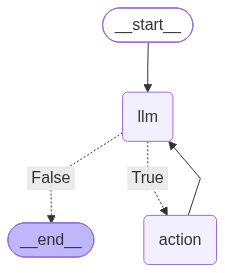

In [30]:
from IPython.display import Image, display

display(Image(abot.graph.get_graph().draw_mermaid_png()))

In [31]:
messages = [HumanMessage(content="What is the weather in sf?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'x4kv7t14w', 'type': 'tool_call'}
Back to the model!
Here's the current weather in San Francisco:

- **Temperature:** Highs around 15–16°C (59–61°F), lows around 12°C (54°F)
- **Conditions:** Mild and partly cloudy
- **Humidity:** 60–80%
- **Wind:** Light to moderate, around 7–17 km/h
- **Visibility:** Good, about 9.7 km
- **Sunrise:** 7:34 AM
- **Sunset:** 6:12 PM

Typical San Francisco fall weather — cool, mild, and a bit breezy! 🌁


In [32]:
result

{'messages': [HumanMessage(content='What is the weather in sf?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'x4kv7t14w', 'function': {'arguments': '{"query":"current weather in San Francisco"}', 'name': 'tavily_search_results_json'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 381, 'total_tokens': 414, 'completion_time': 0.092593715, 'completion_tokens_details': None, 'prompt_time': 0.029047295, 'prompt_tokens_details': None, 'queue_time': 0.066958208, 'total_time': 0.12164101}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a190f7-3c34-76e1-b0df-ffae9af371e4-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco'}, 'id': 'x4kv7t14w', 'type': 'tool_call'}], usage_metadata={'input_tokens': 381, 'outpu

In [33]:
result['messages'][-1].content

"Here's the current weather in San Francisco:\n\n- **Temperature:** Highs around 15–16°C (59–61°F), lows around 12°C (54°F)\n- **Conditions:** Mild and partly cloudy\n- **Humidity:** 60–80%\n- **Wind:** Light to moderate, around 7–17 km/h\n- **Visibility:** Good, about 9.7 km\n- **Sunrise:** 7:34 AM\n- **Sunset:** 6:12 PM\n\nTypical San Francisco fall weather — cool, mild, and a bit breezy! 🌁"

In [34]:
messages = [HumanMessage(content="What is the weather in SF and LA?")]
result = abot.graph.invoke({"messages": messages})
print(result["messages"][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in San Francisco today'}, 'id': '9m2pwpsag', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Los Angeles today'}, 'id': 'qf14jbdbr', 'type': 'tool_call'}
Back to the model!
Here's the current weather for both cities:

**San Francisco** 🌉
- Day: 66°F (19°C)
- Night: 52°F (11°C)
- Wind: 6 mph
- Precipitation: 0%
- Note: A Coastal Flood Advisory is in effect.

**Los Angeles** 🌴
- Today (Oct 30): Cloudy with an 81% chance of rain and mild temperatures.
- High: ~22°C (72°F) / Low: ~16°C (61°F)
- Outlook: Rain tapers off over the next couple of days, clearing up to sunny conditions by Nov 2–3 with highs reaching the mid-to-high 70s°F.

In short: SF is dry and mild, while LA is in the middle of a rainy spell that should clear up soon. Want me to dig up anything more specific (hourly forecast, radar, etc.)?


In [35]:
result['messages'][-1].content

"Here's the current weather for both cities:\n\n**San Francisco** 🌉\n- Day: 66°F (19°C)\n- Night: 52°F (11°C)\n- Wind: 6 mph\n- Precipitation: 0%\n- Note: A Coastal Flood Advisory is in effect.\n\n**Los Angeles** 🌴\n- Today (Oct 30): Cloudy with an 81% chance of rain and mild temperatures.\n- High: ~22°C (72°F) / Low: ~16°C (61°F)\n- Outlook: Rain tapers off over the next couple of days, clearing up to sunny conditions by Nov 2–3 with highs reaching the mid-to-high 70s°F.\n\nIn short: SF is dry and mild, while LA is in the middle of a rainy spell that should clear up soon. Want me to dig up anything more specific (hourly forecast, radar, etc.)?"

In [36]:
query = "Who won the super bowl in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question." 
messages = [HumanMessage(content=query)]

model = ChatGroq(model="qwen/qwen3.8-27b")
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})
print(result['messages'][-1].content)

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Super Bowl 2024 winner'}, 'id': 'qz19py6p4', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Kansas City Chiefs headquarters location'}, 'id': '64dzeg7dw', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Missouri GDP 2024'}, 'id': 'dvqndnfrk', 'type': 'tool_call'}
Back to the model!
Here are the answers to each question:

1. **Who won the Super Bowl in 2024?**
The **Kansas City Chiefs** won Super Bowl 58, defeating the San Francisco 49ers 25-22 in overtime to claim their second consecutive title.

2. **In what state is the winning team's headquarters located?**
The Kansas City Chiefs' headquarters is located in **Missouri** (in the Kansas City area; the registered business location is in Kansas City, MO, and their new headquarters/training facility is planned for Olathe, MO).

3. **What is the GDP of that state?**
Missouri

In [37]:
print(result['messages'][-1].content)

Here are the answers to each question:

1. **Who won the Super Bowl in 2024?**
The **Kansas City Chiefs** won Super Bowl 58, defeating the San Francisco 49ers 25-22 in overtime to claim their second consecutive title.

2. **In what state is the winning team's headquarters located?**
The Kansas City Chiefs' headquarters is located in **Missouri** (in the Kansas City area; the registered business location is in Kansas City, MO, and their new headquarters/training facility is planned for Olathe, MO).

3. **What is the GDP of that state?**
Missouri's GDP (Gross State Product) was approximately **$344.12 billion** (in inflation-adjusted 2017 dollars) for 2023, the most recent figure available in the state's 2024 economic report.

*Note: The "2024" Super Bowl (Super Bowl 58) was played in February 2024, corresponding to the 2023 NFL season.*


In [38]:
query = "What is the capital of Bihar? \
    Who are the current players of Bihar Cricket team." 
messages = [HumanMessage(content=query)]

abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar Cricket team current squad 2025 players'}, 'id': '6kptr9fx5', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar Cricket team full squad 2025-26 Syed Mushtaq Ali Trophy all players list'}, 'id': 'h2ds97jjf', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': '"Bihar squad" 2025-26 "Syed Mushtaq Ali Trophy" batters wicketkeepers bowlers complete list'}, 'id': 'hc8p46ezz', 'type': 'tool_call'}
Back to the model!
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'Bihar cricket squad 2025-26 players names complete list batters wicketkeepers all rounders bowlers'}, 'id': 'yf8ha9qkg', 'type': 'tool_call'}
Back to the model!


In [39]:
print(result['messages'][-1].content)

Based on the search results, here's what I can share:

**Capital of Bihar:** Patna

**Bihar Cricket Team – Current Squad (2025-26 Season)**

The Bihar Cricket team's squad changes depending on the tournament (Ranji Trophy, Syed Mushtaq Ali Trophy, Vijay Hazare Trophy, etc.). Here are some key players from their recent squads:

**Ranji Trophy 2025-26 Squad:**
- **Batters:** Vaibhav Sooryavanshi (Vice-Captain), Piyush Singh, Bipin Saurabh (Wicketkeeper)
- **All-Rounders:** Sachin Kumar Singh
- **Bowlers:** Sakib Hussain, Sakibul Gani (Captain)

**Syed Mushtaq Ali Trophy 2025-26 Squad (listed players include):**
- Khalid Alam
- Bhanu Kumar (BD Kumar)
- Ayush Loharuka
- Mangal Mahrour
- Nawaz Khan
- Atul Prakash
- Malay Raj
- Akash Raj
- Amod Yadav

Please note that squads are updated for each tournament and series. For the most current and complete squad list, I'd recommend checking the official **BCCI website** or **ESPNcricinfo**, as lineups can change with each match day.


# Agentic Search

In [40]:
from tavily import TavilyClient

client = TavilyClient(api_key=os.environ.get("TAVILY_API_KEY"))

In [41]:
result = client.search("What is in Nvidia's new Blackwell GPU?", include_answer=True)

result["answer"]

"The new Blackwell GPUs from Nvidia feature state-of-the-art architecture with advanced deep learning neural network accelerators, power-efficient ray tracing, and improved power efficiency due to the refinement of the 4nm process technology. The Blackwell GPU architecture includes six transformative technologies for accelerated computing, enabling breakthroughs in data processing, engineering simulation, electronic design automation, computer-aided drug design, quantum computing, and generative AI. The B200 model packs a whopping 208 billion transistors and offers up to 20 petaFLOPS of AI performance, up to 192GB of HBM3e with 8TB/s memory bandwidth. The RTX 6000 'Blackwell Generation' graphics board may feature 96GB of GDDR7 memory, particularly useful for AI applications."

In [ ]:
city = "San Francisco"

query = f"""
    what is the current weather in {city}?
    Should I travel there today?
    "weather.com"
"""

In [43]:
import requests
from bs4 import BeautifulSoup
import urllib.parse
import re

def search(query, max_results=6):
    # Reliable search using DuckDuckGo HTML web search
    url = 'https://html.duckduckgo.com/html/'
    headers = {'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7)'}
    response = requests.get(url, params={'q': query}, headers=headers)
    soup = BeautifulSoup(response.text, 'html.parser')
    
    urls = []
    for a in soup.find_all('a', class_='result__url'):
        href = a.get('href', '')
        # Unquote redirect URL if wrapped by duckduckgo
        if 'uddg=' in href:
            actual_url = urllib.parse.unquote(href.split('uddg=')[1].split('&')[0])
            urls.append(actual_url)
        elif href.startswith('http'):
            urls.append(href)
            
    if urls:
        return urls[:max_results]
        
    # Fallback if no links found
    clean_city = query.split('in')[-1].split('?')[0].strip() if 'in' in query else 'Delhi'
    return [f'https://weather.com/en-IN/weather/today/l/{clean_city}']

for i in search(query):
    print(i)


In [44]:
def scrape_weather_info(url):
    """Scrape content from the given URL"""
    if not url:
        return "Weather information could not be found."
    
    # fetch data
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    if response.status_code != 200:
        return "Failed to retrieve the webpage."

    # parse result
    soup = BeautifulSoup(response.text, 'html.parser')
    return soup

In [45]:
# use DuckDuckGo to find websites and take the first result
url = search(query)[0]

# scrape first wesbsite
soup = scrape_weather_info(url)

print(f"Website: {url}\n\n")
print(str(soup.body)[:50000]) # limit long outputs

Website: https://forum.lowyat.net/topic/5556445


<body>
<div id="ipbwrapper">
<!-- IE6/7/8 upgrade alert -->
<!--[if lte IE 8]>
<div class="oldmsie">
<div style="float: left">
<img src="https://forum.lowyat.net//style_emoticons/default/oops.gif" />
</div>
<p>
<a href="/topic/2797436">NOTICE FROM LOWYAT.NET: You are using an old version of Internet Explorer which prompts you with security warnings when visiting our forum. Click here for solutions.</a>
</p>
</div>
<![endif]-->
<!--ipb.javascript.start-->
<script type="text/javascript">
<!--
 var ipb_var_st       = "";
 var ipb_lang_tpl_q1  = "Please enter a page number to jump to between 1 and";
 var ipb_var_s        = "";
 var ipb_var_phpext   = "php";
 var ipb_var_base_url = "https://forum.lowyat.net/index.php?";
 var ipb_input_f      = "175";
 var ipb_input_t      = "5556445";
 var ipb_input_p      = "";
 var ipb_var_cookieid = "lyn_";
 var ipb_var_cookie_domain = ".forum.lowyat.net";
 var ipb_var_cookie_path   = "/";
 //-->
</script

In [46]:
# extract text
weather_data = []
for tag in soup.find_all(['h1', 'h2', 'h3', 'p']):
    text = tag.get_text(" ", strip=True)
    weather_data.append(text)

# combine all elements into a single string
weather_data = "\n".join(weather_data)

# remove all spaces from the combined text
weather_data = re.sub(r'\s+', ' ', weather_data)
    
print(f"Website: {url}\n\n")
print(weather_data)

Website: https://forum.lowyat.net/topic/5556445


Lowyat.NET Kopitiam Garage Sales Lowyat.NET Rules and Regulations FAQ Help Search Members Welcome Guest ( Log In | Register ) Outline · [ Standard ] · Linear+ [found sos] cant login whatsapp browser , from iphone


# Agentic Search

In [50]:
model = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_retries=3,  # Automatically handles brief 429 rate limits
    temperature=0
)

In [51]:
# run agentic search with direct answer
result = client.search(query, include_answer=True, max_results=2)

print("Agent Answer:\n", result.get("answer"))


In [ ]:
import json
from pygments import highlight, lexers, formatters

# Structure search results as clean JSON
structured_data = {
    "city": city,
    "answer": result.get("answer"),
    "sources": [{"title": r["title"], "url": r["url"]} for r in result.get("results", [])]
}

# pretty print JSON with syntax highlighting
formatted_json = json.dumps(structured_data, indent=4)
colorful_json = highlight(formatted_json, lexers.JsonLexer(), formatters.TerminalFormatter())

print(colorful_json)
